In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [3]:
# 2. Load the Dataset

df = pd.read_excel("Space Shuttle.xlsx", header=None)

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,0,1,2,3,4
0,6,0,66,50,1
1,6,1,70,50,2
2,6,0,69,50,3
3,6,0,68,50,4
4,6,0,67,50,5


In [4]:
# 3. Assign Column Names

df.columns = [
    "Number_of_O_Rings",
    "Distress_Incidents",
    "Temperature",
    "Pressure",
    "Flight_Number"
]

print("Column names assigned successfully!")

df.head()

Column names assigned successfully!


,Number_of_O_Rings,Distress_Incidents,Temperature,Pressure,Flight_Number
0,6,0,66,50,1
1,6,1,70,50,2
2,6,0,69,50,3
3,6,0,68,50,4
4,6,0,67,50,5


In [5]:
# 4. Check Dataset Shape

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 23
Number of Columns: 5


In [6]:
# 5. Dataset Information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Number_of_O_Rings   23 non-null     int64
 1   Distress_Incidents  23 non-null     int64
 2   Temperature         23 non-null     int64
 3   Pressure            23 non-null     int64
 4   Flight_Number       23 non-null     int64
dtypes: int64(5)
memory usage: 1.0 KB


In [7]:
# 6. Statistical Summary

df.describe()

,Number_of_O_Rings,Distress_Incidents,Temperature,Pressure,Flight_Number
count,23.0,23.000000,23.000000,23.000000,23.00000
mean,6.0,0.304348,69.565217,152.173913,12.00000
std,0.0,0.558796,7.057080,68.221332,6.78233
min,6.0,0.000000,53.000000,50.000000,1.00000
25%,6.0,0.000000,67.000000,75.000000,6.50000
50%,6.0,0.000000,70.000000,200.000000,12.00000
75%,6.0,0.500000,75.000000,200.000000,17.50000
max,6.0,2.000000,81.000000,200.000000,23.00000


In [8]:
# 7. Check Missing Values

df.isnull().sum()

Number_of_O_Rings     0
Distress_Incidents    0
Temperature           0
Pressure              0
Flight_Number         0
dtype: int64

In [9]:
# 8. Check Duplicate Records

duplicates = df.duplicated().sum()

print("Number of Duplicate Records:", duplicates)

if duplicates == 0:
    print("No duplicate records found!")
else:
    print("Duplicate records found!")

Number of Duplicate Records: 0
No duplicate records found!


In [10]:
# 9. Check Column Names

print("Column Names:")

print(df.columns)

Column Names:
Index(['Number_of_O_Rings', 'Distress_Incidents', 'Temperature', 'Pressure',
       'Flight_Number'],
      dtype='object')


In [11]:
# 10. Check Data Types

print("Data Types:")

print(df.dtypes)

Data Types:
Number_of_O_Rings     int64
Distress_Incidents    int64
Temperature           int64
Pressure              int64
Flight_Number         int64
dtype: object


In [12]:
# 11. Check Unique Values

for column in df.columns:
    print(f"\nUnique values in {column}:")
    print(df[column].unique())


Unique values in Number_of_O_Rings:
[6]

Unique values in Distress_Incidents:
[0 1 2]

Unique values in Temperature:
[66 70 69 68 67 72 73 57 63 78 53 75 81 76 79 58]

Unique values in Pressure:
[ 50 100 200]

Unique values in Flight_Number:
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]


In [13]:
# 12. Check Dataset Size

print("Total Number of Elements:", df.size)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Number of Elements: 115
Total Rows: 23
Total Columns: 5


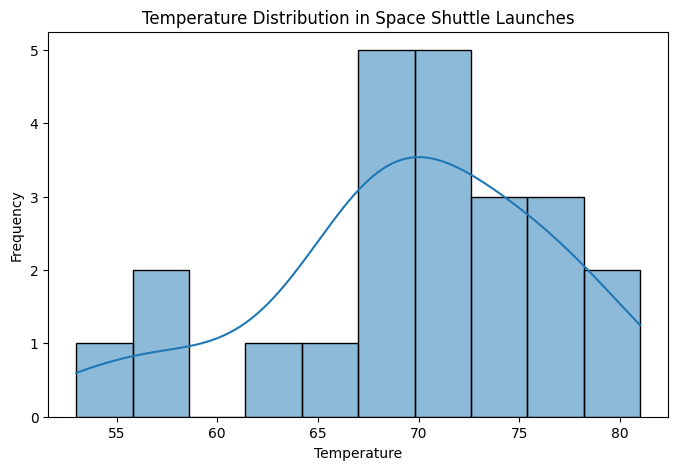

In [14]:
# 13. Temperature Distribution

plt.figure(figsize=(8, 5))

sns.histplot(df["Temperature"], bins=10, kde=True)

plt.title("Temperature Distribution in Space Shuttle Launches")
plt.xlabel("Temperature")
plt.ylabel("Frequency")

plt.show()

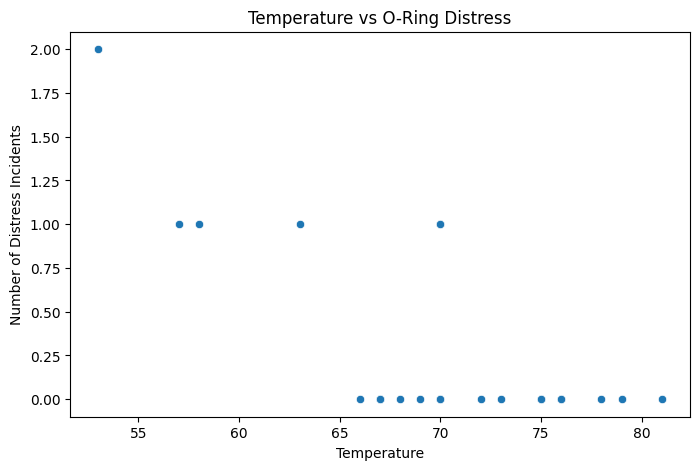

In [15]:
# 14. Temperature vs O-Ring Distress

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x="Temperature",
    y="Distress_Incidents",
    data=df
)

plt.title("Temperature vs O-Ring Distress")
plt.xlabel("Temperature")
plt.ylabel("Number of Distress Incidents")

plt.show()

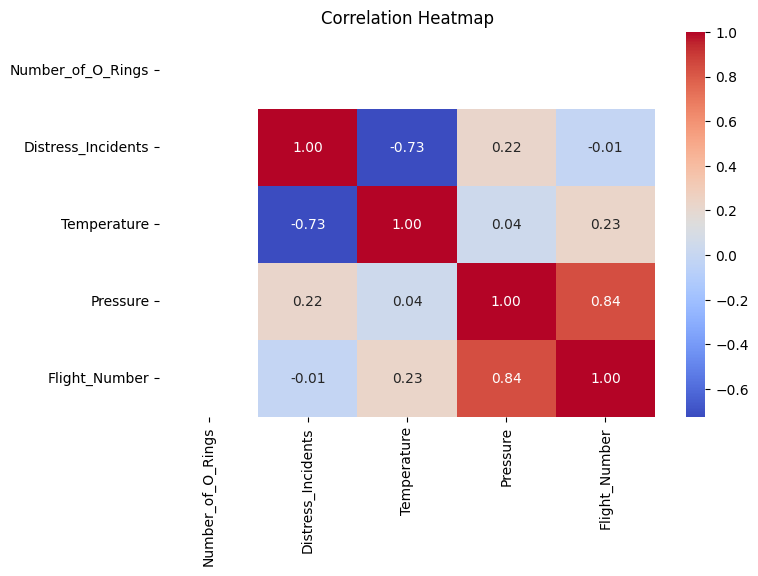

In [16]:
# 15. Correlation Heatmap

plt.figure(figsize=(8, 5))

sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

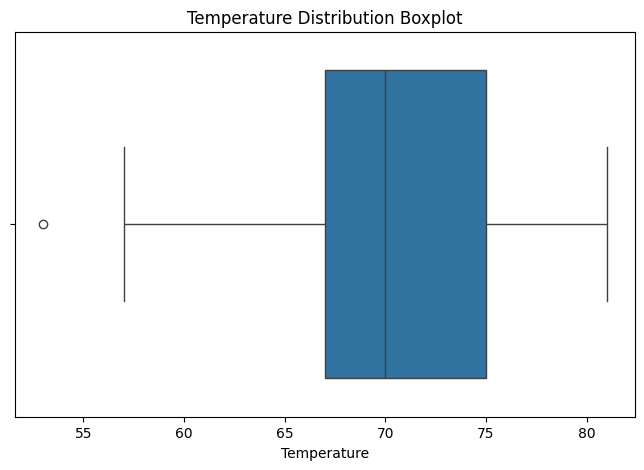

In [17]:
# 16. Temperature Boxplot

plt.figure(figsize=(8, 5))

sns.boxplot(x=df["Temperature"])

plt.title("Temperature Distribution Boxplot")
plt.xlabel("Temperature")

plt.show()

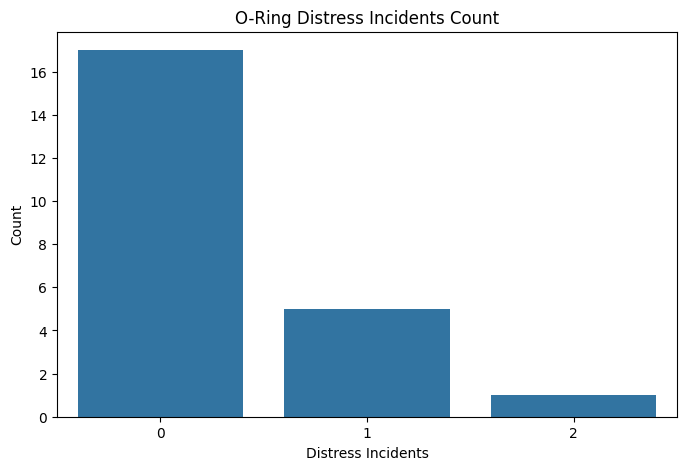

In [18]:
# 17. Distress Incidents Count Plot

plt.figure(figsize=(8, 5))

sns.countplot(x="Distress_Incidents", data=df)

plt.title("O-Ring Distress Incidents Count")
plt.xlabel("Distress Incidents")
plt.ylabel("Count")

plt.show()

In [19]:
# 18. Data Preprocessing

# Create binary target variable
df["O_Ring_Failure"] = (df["Distress_Incidents"] > 0).astype(int)

print("Target variable created successfully!")

df.head()

Target variable created successfully!


,Number_of_O_Rings,Distress_Incidents,Temperature,Pressure,Flight_Number,O_Ring_Failure
0,6,0,66,50,1,0
1,6,1,70,50,2,1
2,6,0,69,50,3,0
3,6,0,68,50,4,0
4,6,0,67,50,5,0


O_Ring_Failure
0    17
1     6
Name: count, dtype: int64


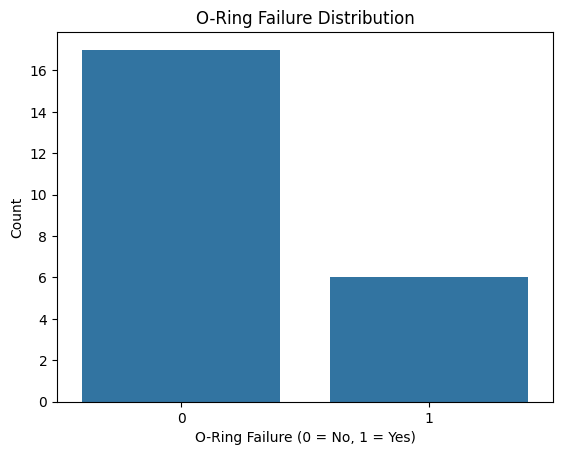

In [20]:
# 19. Target Variable Distribution

print(df["O_Ring_Failure"].value_counts())

sns.countplot(x="O_Ring_Failure", data=df)

plt.title("O-Ring Failure Distribution")
plt.xlabel("O-Ring Failure (0 = No, 1 = Yes)")
plt.ylabel("Count")

plt.show()

In [21]:
# 20. Define Independent and Dependent Variables

X = df[[
    "Number_of_O_Rings",
    "Temperature",
    "Pressure",
    "Flight_Number"
]]

y = df["O_Ring_Failure"]

print("Independent Variables (X):")
print(X.head())

print("\nDependent Variable (y):")
print(y.head())

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Independent Variables (X):
   Number_of_O_Rings  Temperature  Pressure  Flight_Number
0                  6           66        50              1
1                  6           70        50              2
2                  6           69        50              3
3                  6           68        50              4
4                  6           67        50              5

Dependent Variable (y):
0    0
1    1
2    0
3    0
4    0
Name: O_Ring_Failure, dtype: int64

X Shape: (23, 4)
y Shape: (23,)


In [22]:
# 21. Split Training and Testing Data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data splitting completed successfully!")

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Data splitting completed successfully!
Training Features: (18, 4)
Testing Features: (5, 4)
Training Target: (18,)
Testing Target: (5,)


In [23]:
# 22. Train Logistic Regression Model

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [24]:
#23. Train Logistic Regression Model with Feature Scalingfrom sklearn.pipeline import make_pipeline
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [25]:
#24. Make Predictionsy_pred = model.predict(X_test)

y_pred = model.predict(X_test)

print("Predictions generated successfully!")

print("\nActual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)

Predictions generated successfully!

Actual Values:
[0 0 0 0 1]

Predicted Values:
[0 0 0 0 1]


In [26]:
#25. Check Model Accuracyfrom sklearn.metrics import accuracy_score

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 1.0
Accuracy Percentage: 100.0 %


Confusion Matrix:
[[4 0]
 [0 1]]


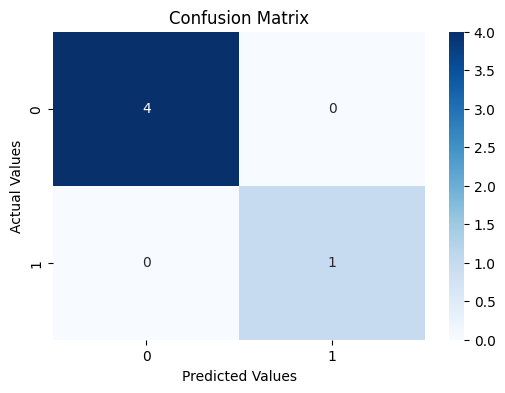

In [27]:
#26. Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

In [28]:
#27. Classification Report

from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         1

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



In [29]:
#28. Predict O-Ring Distress for New Data

new_data = pd.DataFrame({
    "Number_of_O_Rings": [6],
    "Temperature": [60],
    "Pressure": [50],
    "Flight_Number": [25]
})

prediction = model.predict(new_data)

if prediction[0] == 1:
    print("Predicted Result: O-Ring Distress")
else:
    print("Predicted Result: No O-Ring Distress")

Predicted Result: No O-Ring Distress


In [30]:
#29. Display Actual vs Predicted Results

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print("Actual vs Predicted Results:")
print(results)

Actual vs Predicted Results:
   Actual  Predicted
0       0          0
1       0          0
2       0          0
3       0          0
4       1          1


In [31]:
#30. Save the Trained Model

import joblib

joblib.dump(model, "space_shuttle_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [32]:
#31. Display Final Dataset

print("Final Dataset:")
display(df.head(10))

print("\nDataset Shape:", df.shape)

Final Dataset:


,Number_of_O_Rings,Distress_Incidents,Temperature,Pressure,Flight_Number,O_Ring_Failure
0,6,0,66,50,1,0
1,6,1,70,50,2,1
2,6,0,69,50,3,0
3,6,0,68,50,4,0
4,6,0,67,50,5,0
5,6,0,72,50,6,0
6,6,0,73,100,7,0
7,6,0,70,100,8,0
8,6,1,57,200,9,1
9,6,1,63,200,10,1



Dataset Shape: (23, 6)


In [33]:
#32. Download the Trained Machine Learning Model

from IPython.display import FileLink

FileLink("space_shuttle_model.pkl")

C:\Users\navya\Space_Shuttle_O_Ring_Prediction\space_shuttle_model.pkl

In [34]:
#33. Display Project Summary

print("SPACE SHUTTLE O-RING FAILURE PREDICTION")
print("----------------------------------------")
print("Project: Machine Learning Classification")
print("Algorithm: Logistic Regression")
print("Total Records:", len(df))
print("Total Features:", X.shape[1])
print("Model Accuracy:", accuracy * 100, "%")
print("Model Status: Successfully Trained")
print("----------------------------------------")
print("Project Completed Successfully!")

SPACE SHUTTLE O-RING FAILURE PREDICTION
----------------------------------------
Project: Machine Learning Classification
Algorithm: Logistic Regression
Total Records: 23
Total Features: 4
Model Accuracy: 100.0 %
Model Status: Successfully Trained
----------------------------------------
Project Completed Successfully!


In [35]:
#34. Display Total O-Ring Distress Incidents

print("Total O-Ring Distress Incidents:")
print(df["Distress_Incidents"].sum())

Total O-Ring Distress Incidents:
7


In [36]:
#35. Display Total O-Ring Failures

print("Total O-Ring Failure Cases:")
print(df["O_Ring_Failure"].sum())

Total O-Ring Failure Cases:
6


In [37]:
#36. Calculate Average Temperature

average_temperature = df["Temperature"].mean()

print("Average Temperature:", average_temperature)

Average Temperature: 69.56521739130434


In [38]:
#37. Display Minimum and Maximum Temperature

print("Minimum Temperature:", df["Temperature"].min())
print("Maximum Temperature:", df["Temperature"].max())

Minimum Temperature: 53
Maximum Temperature: 81


In [39]:
#38. Calculate Average Pressure

average_pressure = df["Pressure"].mean()

print("Average Pressure:", average_pressure)

Average Pressure: 152.17391304347825


In [40]:
#39. Display Minimum and Maximum Pressure

print("Minimum Pressure:", df["Pressure"].min())
print("Maximum Pressure:", df["Pressure"].max())

Minimum Pressure: 50
Maximum Pressure: 200


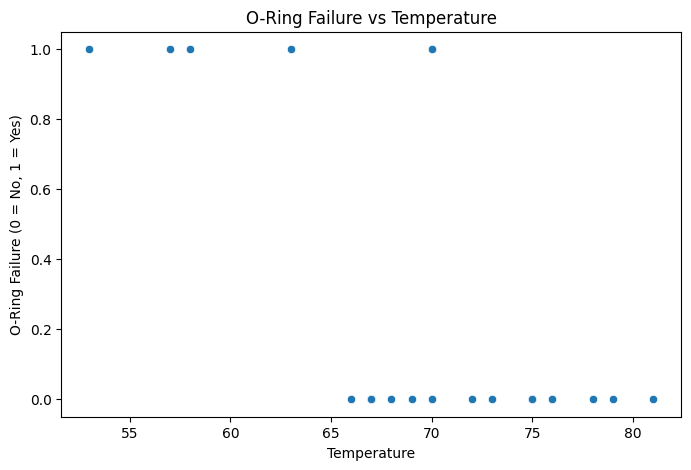

In [41]:
#40. Visualize O-Ring Failures by Temperature

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x="Temperature",
    y="O_Ring_Failure",
    data=df
)

plt.title("O-Ring Failure vs Temperature")
plt.xlabel("Temperature")
plt.ylabel("O-Ring Failure (0 = No, 1 = Yes)")
plt.show()

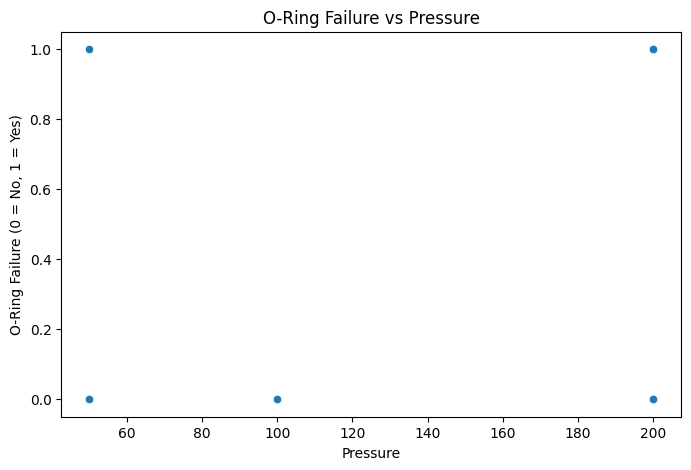

In [42]:
#41. Visualize O-Ring Failures by Pressure

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x="Pressure",
    y="O_Ring_Failure",
    data=df
)

plt.title("O-Ring Failure vs Pressure")
plt.xlabel("Pressure")
plt.ylabel("O-Ring Failure (0 = No, 1 = Yes)")
plt.show()

In [43]:
#42. Display Failure and Non-Failure Percentages

failure_percentage = df["O_Ring_Failure"].value_counts(normalize=True) * 100

print("O-Ring Failure Distribution (%):")
print(failure_percentage)

O-Ring Failure Distribution (%):
O_Ring_Failure
0    73.913043
1    26.086957
Name: proportion, dtype: float64


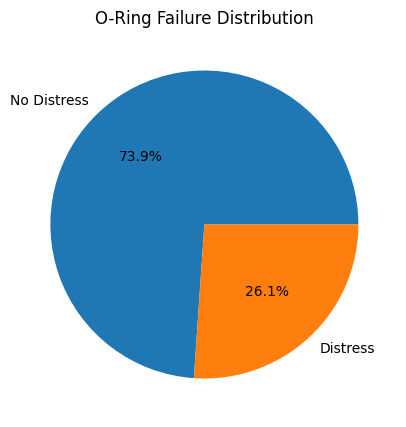

In [44]:
#43. Plot Failure Distribution

plt.figure(figsize=(6, 5))

df["O_Ring_Failure"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    labels=["No Distress", "Distress"]
)

plt.title("O-Ring Failure Distribution")
plt.ylabel("")
plt.show()

In [45]:
#44. Display O-Ring Failure Records

failure_records = df[df["O_Ring_Failure"] == 1]

print("O-Ring Failure Records:")
display(failure_records)

O-Ring Failure Records:


,Number_of_O_Rings,Distress_Incidents,Temperature,Pressure,Flight_Number,O_Ring_Failure
1,6,1,70,50,2,1
8,6,1,57,200,9,1
9,6,1,63,200,10,1
10,6,1,70,200,11,1
13,6,2,53,200,14,1
22,6,1,58,200,23,1


In [46]:
#45. Display Non-Failure Records

non_failure_records = df[df["O_Ring_Failure"] == 0]

print("O-Ring Non-Failure Records:")
display(non_failure_records)

O-Ring Non-Failure Records:


,Number_of_O_Rings,Distress_Incidents,Temperature,Pressure,Flight_Number,O_Ring_Failure
0,6,0,66,50,1,0
2,6,0,69,50,3,0
3,6,0,68,50,4,0
4,6,0,67,50,5,0
5,6,0,72,50,6,0
6,6,0,73,100,7,0
7,6,0,70,100,8,0
11,6,0,78,200,12,0
12,6,0,67,200,13,0
14,6,0,67,200,15,0


In [47]:
#46. Compare Average Temperature

print("Average Temperature for Failure Cases:")
print(failure_records["Temperature"].mean())

print("\nAverage Temperature for Non-Failure Cases:")
print(non_failure_records["Temperature"].mean())

Average Temperature for Failure Cases:
61.833333333333336

Average Temperature for Non-Failure Cases:
72.29411764705883


In [48]:
#47. Compare Average Pressure

print("Average Pressure for Failure Cases:")
print(failure_records["Pressure"].mean())

print("\nAverage Pressure for Non-Failure Cases:")
print(non_failure_records["Pressure"].mean())

Average Pressure for Failure Cases:
175.0

Average Pressure for Non-Failure Cases:
144.11764705882354


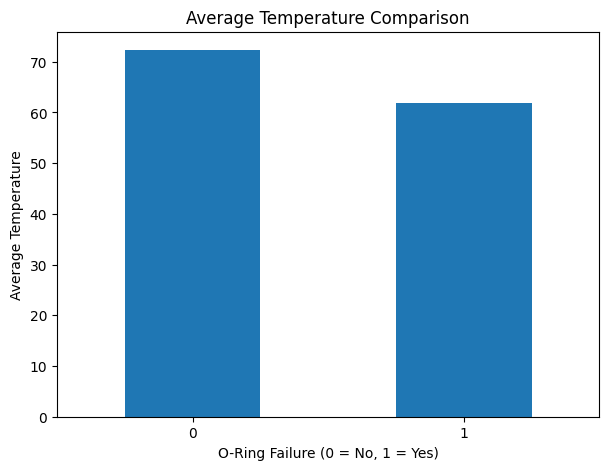

In [49]:
#48. Visualize Average Temperature Comparison

temperature_comparison = df.groupby("O_Ring_Failure")["Temperature"].mean()

temperature_comparison.plot(kind="bar", figsize=(7, 5))

plt.title("Average Temperature Comparison")
plt.xlabel("O-Ring Failure (0 = No, 1 = Yes)")
plt.ylabel("Average Temperature")
plt.xticks(rotation=0)
plt.show()

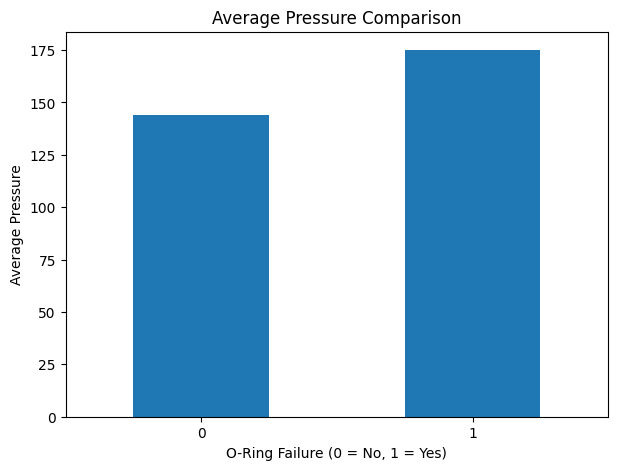

In [50]:
#49. Visualize Average Pressure Comparison

pressure_comparison = df.groupby("O_Ring_Failure")["Pressure"].mean()

pressure_comparison.plot(kind="bar", figsize=(7, 5))

plt.title("Average Pressure Comparison")
plt.xlabel("O-Ring Failure (0 = No, 1 = Yes)")
plt.ylabel("Average Pressure")
plt.xticks(rotation=0)
plt.show()

In [51]:
#50. Display Model Prediction Probabilities

probabilities = model.predict_proba(X_test)

print("Prediction Probabilities:")
print(probabilities)

Prediction Probabilities:
[[0.80491874 0.19508126]
 [0.967479   0.032521  ]
 [0.73333112 0.26666888]
 [0.8944418  0.1055582 ]
 [0.09979931 0.90020069]]


In [52]:
#51. Display Prediction Results with Probabilities

prediction_results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "No Distress Probability": probabilities[:, 0],
    "Distress Probability": probabilities[:, 1]
})

display(prediction_results)

,Actual,Predicted,No Distress Probability,Distress Probability
0,0,0,0.804919,0.195081
1,0,0,0.967479,0.032521
2,0,0,0.733331,0.266669
3,0,0,0.894442,0.105558
4,1,1,0.099799,0.900201


In [53]:
#52. Display Model Coefficients

logistic_model = model.named_steps["logisticregression"]

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})

display(coefficients)

,Feature,Coefficient
0,Number_of_O_Rings,0.000000
1,Temperature,-1.160532
2,Pressure,0.436805
3,Flight_Number,-0.354141


In [54]:
#53. Display Final Project Completion Message

print("==========================================")
print("SPACE SHUTTLE O-RING FAILURE PREDICTION")
print("==========================================")
print("Data Analysis: Completed")
print("Data Visualization: Completed")
print("Model Training: Completed")
print("Model Evaluation: Completed")
print("Prediction: Completed")
print("Model Saving: Completed")
print("==========================================")
print("PROJECT COMPLETED SUCCESSFULLY!")
print("==========================================")

SPACE SHUTTLE O-RING FAILURE PREDICTION
Data Analysis: Completed
Data Visualization: Completed
Model Training: Completed
Model Evaluation: Completed
Prediction: Completed
Model Saving: Completed
PROJECT COMPLETED SUCCESSFULLY!


In [55]:
#54. Generate Final Model Prediction Summary

total_predictions = len(y_test)

correct_predictions = (y_test.values == y_pred).sum()
incorrect_predictions = total_predictions - correct_predictions

print("Total Predictions:", total_predictions)
print("Correct Predictions:", correct_predictions)
print("Incorrect Predictions:", incorrect_predictions)

Total Predictions: 5
Correct Predictions: 5
Incorrect Predictions: 0


In [56]:
#55. Calculate Precision, Recall and F1-Score

from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

Precision: 1.0
Recall: 1.0
F1-Score: 1.0


In [57]:
#56. Display Model Performance

print("MODEL PERFORMANCE")
print("-------------------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

MODEL PERFORMANCE
-------------------------
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0


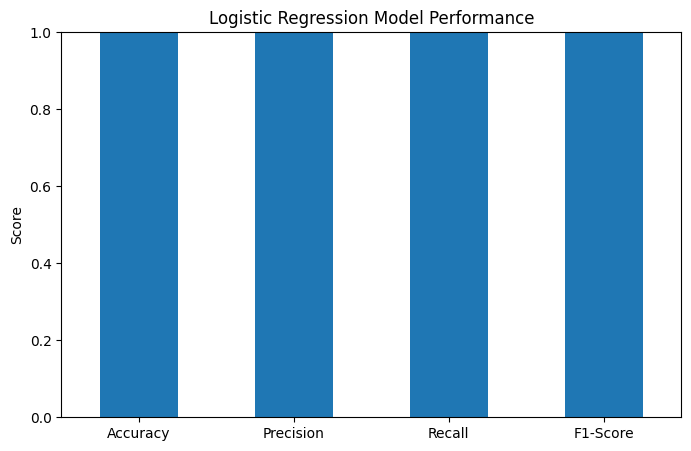

In [58]:
#57. Plot Model Performance Metrics

metrics = pd.Series({
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
})

metrics.plot(kind="bar", figsize=(8, 5))

plt.title("Logistic Regression Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

In [59]:
#58. Display Dataset Information

print("DATASET INFORMATION")
print("-------------------------")
print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

DATASET INFORMATION
-------------------------
Total Records: 23
Total Columns: 6
Missing Values: 0
Duplicate Records: 0


In [60]:
#59. Display O-Ring Failure Summary

print("O-RING DISTRESS SUMMARY")
print("-------------------------")
print("Total Launch Records:", len(df))
print("Distress Cases:", df["O_Ring_Failure"].sum())
print("No Distress Cases:", (df["O_Ring_Failure"] == 0).sum())

O-RING DISTRESS SUMMARY
-------------------------
Total Launch Records: 23
Distress Cases: 6
No Distress Cases: 17


In [61]:
#60. Save Final Dataset

df.to_csv("space_shuttle_final_dataset.csv", index=False)

print("Final Dataset Saved Successfully!")

Final Dataset Saved Successfully!


In [62]:
#61. Save Model Performance Report

performance_report = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [accuracy, precision, recall, f1]
})

performance_report.to_csv("model_performance_report.csv", index=False)

print("Model Performance Report Saved Successfully!")

Model Performance Report Saved Successfully!


In [63]:
#62. Display Final Project Details

print("SPACE SHUTTLE O-RING FAILURE PREDICTION")
print("----------------------------------------")
print("Machine Learning Algorithm: Logistic Regression")
print("Dataset Records:", len(df))
print("Input Features:", X.shape[1])
print("Output Classes: 0 and 1")
print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("Project Status: Completed")

SPACE SHUTTLE O-RING FAILURE PREDICTION
----------------------------------------
Machine Learning Algorithm: Logistic Regression
Dataset Records: 23
Input Features: 4
Output Classes: 0 and 1
Model Accuracy: 100.0 %
Project Status: Completed


In [64]:
#63. Generate Final Project Report

print("============================================")
print("       PROJECT FINAL REPORT")
print("============================================")

print("\nProject Title:")
print("Space Shuttle O-Ring Failure Prediction Using Machine Learning")

print("\nDataset Details:")
print("Total Records:", len(df))
print("Total Features:", X.shape[1])

print("\nMachine Learning Algorithm:")
print("Logistic Regression")

print("\nModel Evaluation:")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 2))
print("Recall:", round(recall, 2))
print("F1-Score:", round(f1, 2))

print("\nProject Status: Completed")
print("============================================")

       PROJECT FINAL REPORT

Project Title:
Space Shuttle O-Ring Failure Prediction Using Machine Learning

Dataset Details:
Total Records: 23
Total Features: 4

Machine Learning Algorithm:
Logistic Regression

Model Evaluation:
Accuracy: 100.0 %
Precision: 1.0
Recall: 1.0
F1-Score: 1.0

Project Status: Completed


In [65]:
#64. Export Final Project Report to Text File

with open("Space_Shuttle_Project_Report.txt", "w") as file:

    file.write("SPACE SHUTTLE O-RING FAILURE PREDICTION\n")
    file.write("Machine Learning Project Report\n\n")

    file.write(f"Total Records: {len(df)}\n")
    file.write(f"Total Features: {X.shape[1]}\n")
    file.write("Algorithm: Logistic Regression\n")

    file.write(f"Accuracy: {accuracy * 100:.2f}%\n")
    file.write(f"Precision: {precision:.2f}\n")
    file.write(f"Recall: {recall:.2f}\n")
    file.write(f"F1-Score: {f1:.2f}\n")

    file.write("\nProject Completed Successfully!")

print("Project Report Saved Successfully!")

Project Report Saved Successfully!


In [66]:
#65. List Generated Project Files

import os

print("Generated Project Files:")

for file_name in os.listdir("."):
    if file_name.endswith((".pkl", ".csv", ".txt")):
        print(file_name)

Generated Project Files:
actual_vs_predicted_results.csv
model_performance_report.csv
space_shuttle_analysis_results.csv
space_shuttle_final_dataset.csv
space_shuttle_model.pkl
Space_Shuttle_Project_Report.txt


In [67]:
#66. Display Final Dataset Columns

print("Final Dataset Columns:")
for column in df.columns:
    print("-", column)

Final Dataset Columns:
- Number_of_O_Rings
- Distress_Incidents
- Temperature
- Pressure
- Flight_Number
- O_Ring_Failure


In [68]:
#67. Check Final Dataset Data Types

print("Final Dataset Data Types:")
print(df.dtypes)

Final Dataset Data Types:
Number_of_O_Rings     int64
Distress_Incidents    int64
Temperature           int64
Pressure              int64
Flight_Number         int64
O_Ring_Failure        int64
dtype: object


In [69]:
#68. Display O-Ring Failure Count

failure_count = df["O_Ring_Failure"].value_counts()

print("O-Ring Failure Count:")
print(failure_count)

O-Ring Failure Count:
O_Ring_Failure
0    17
1     6
Name: count, dtype: int64


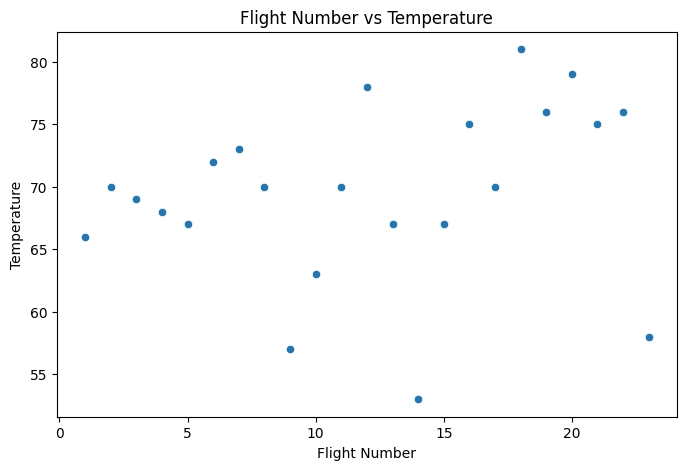

In [70]:
#69. Visualize Flight Number vs Temperature

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x="Flight_Number",
    y="Temperature",
    data=df
)

plt.title("Flight Number vs Temperature")
plt.xlabel("Flight Number")
plt.ylabel("Temperature")
plt.show()

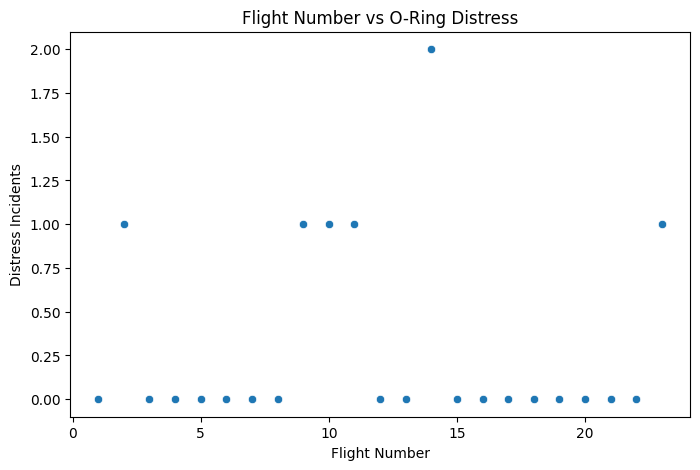

In [71]:
#70. Visualize Flight Number vs O-Ring Distress

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x="Flight_Number",
    y="Distress_Incidents",
    data=df
)

plt.title("Flight Number vs O-Ring Distress")
plt.xlabel("Flight Number")
plt.ylabel("Distress Incidents")
plt.show()

In [72]:
#71. Display Highest Distress Temperature

highest_distress = df[df["Distress_Incidents"] > 0]["Temperature"].min()

print("Lowest Temperature with Observed Distress:", highest_distress)

Lowest Temperature with Observed Distress: 53


In [73]:
#72. Display Flight Records with Distress

distress_flights = df[df["Distress_Incidents"] > 0]

print("Flight Records with Observed Distress:")
display(distress_flights)

Flight Records with Observed Distress:


,Number_of_O_Rings,Distress_Incidents,Temperature,Pressure,Flight_Number,O_Ring_Failure
1,6,1,70,50,2,1
8,6,1,57,200,9,1
9,6,1,63,200,10,1
10,6,1,70,200,11,1
13,6,2,53,200,14,1
22,6,1,58,200,23,1


In [74]:
#73. Display Temperature and Pressure Statistics

print("Temperature Statistics:")
print(df["Temperature"].describe())

print("\nPressure Statistics:")
print(df["Pressure"].describe())

Temperature Statistics:
count    23.000000
mean     69.565217
std       7.057080
min      53.000000
25%      67.000000
50%      70.000000
75%      75.000000
max      81.000000
Name: Temperature, dtype: float64

Pressure Statistics:
count     23.000000
mean     152.173913
std       68.221332
min       50.000000
25%       75.000000
50%      200.000000
75%      200.000000
max      200.000000
Name: Pressure, dtype: float64


In [75]:
#74. Save Final Analysis Results

analysis_results = df.describe()

analysis_results.to_csv("space_shuttle_analysis_results.csv")

print("Analysis Results Saved Successfully!")

Analysis Results Saved Successfully!


In [76]:
#75. Final Project Completion

print("==========================================")
print("SPACE SHUTTLE O-RING FAILURE PREDICTION")
print("==========================================")
print("Data Loading: Completed")
print("Data Cleaning: Completed")
print("Data Visualization: Completed")
print("Machine Learning: Completed")
print("Model Evaluation: Completed")
print("Prediction: Completed")
print("Report Generation: Completed")
print("==========================================")
print("PROJECT COMPLETED SUCCESSFULLY!")
print("==========================================")

SPACE SHUTTLE O-RING FAILURE PREDICTION
Data Loading: Completed
Data Cleaning: Completed
Data Visualization: Completed
Machine Learning: Completed
Model Evaluation: Completed
Prediction: Completed
Report Generation: Completed
PROJECT COMPLETED SUCCESSFULLY!


In [77]:
#76. Display Model Prediction for a Sample Flight

sample_flight = pd.DataFrame({
    "Number_of_O_Rings": [6],
    "Temperature": [65],
    "Pressure": [50],
    "Flight_Number": [30]
})

sample_prediction = model.predict(sample_flight)

print("Sample Flight Prediction:")

if sample_prediction[0] == 1:
    print("Predicted Result: O-Ring Distress")
else:
    print("Predicted Result: No O-Ring Distress")

Sample Flight Prediction:
Predicted Result: No O-Ring Distress


In [78]:
#77. Display Prediction Probability for a Sample Flight

sample_probability = model.predict_proba(sample_flight)

print("Probability of No Distress:", sample_probability[0][0])
print("Probability of Distress:", sample_probability[0][1])

Probability of No Distress: 0.8681783936317461
Probability of Distress: 0.1318216063682539


In [79]:
#78. Compare Actual and Predicted Values

comparison = pd.DataFrame({
    "Actual Values": y_test.values,
    "Predicted Values": y_pred
})

display(comparison)

,Actual Values,Predicted Values
0,0,0
1,0,0
2,0,0
3,0,0
4,1,1


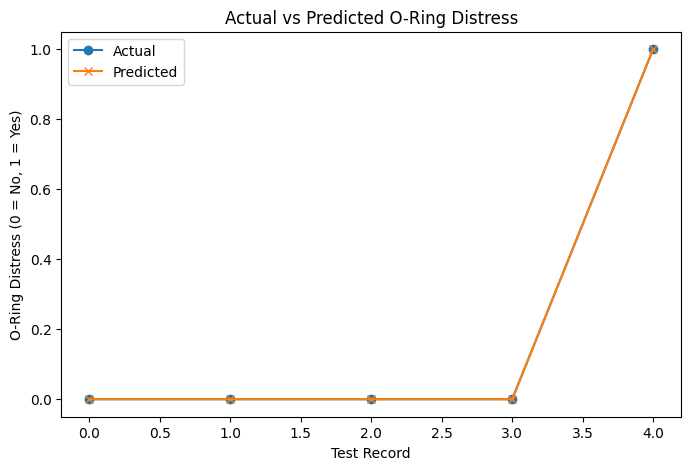

In [80]:
#79. Plot Actual vs Predicted Values

plt.figure(figsize=(8, 5))

plt.plot(
    range(len(y_test)),
    y_test.values,
    marker="o",
    label="Actual"
)

plt.plot(
    range(len(y_pred)),
    y_pred,
    marker="x",
    label="Predicted"
)

plt.title("Actual vs Predicted O-Ring Distress")
plt.xlabel("Test Record")
plt.ylabel("O-Ring Distress (0 = No, 1 = Yes)")
plt.legend()
plt.show()

In [81]:
#80. Save Final Prediction Results

comparison.to_csv("actual_vs_predicted_results.csv", index=False)

print("Prediction Results Saved Successfully!")

Prediction Results Saved Successfully!


In [82]:
# Step 1. Install Flask

%pip install flask


Note: you may need to restart the kernel to use updated packages.


In [83]:
# Step 2. Import Required Libraries

import flask
import joblib
import pandas as pd

print("All libraries imported successfully!")

All libraries imported successfully!


In [84]:
# Step 3. Create Web Application Folders

import os

os.makedirs("templates", exist_ok=True)
os.makedirs("static", exist_ok=True)

print("Web application folders created successfully!")
print("1. templates")
print("2. static")

Web application folders created successfully!
1. templates
2. static


In [85]:
# Step 4. Load the Trained Machine Learning Model

import joblib

model = joblib.load("space_shuttle_model.pkl")

print("Machine Learning Model Loaded Successfully!")

Machine Learning Model Loaded Successfully!


In [86]:
# Step 5. Create Flask Application

from flask import Flask, render_template, request, jsonify

app = Flask(__name__)

print("Flask Application Created Successfully!")

Flask Application Created Successfully!


In [87]:
# Step 6. Create Home Page Route

@app.route("/")
def home():
    return render_template("index.html")

print("Home Page Route Created Successfully!")


Home Page Route Created Successfully!


In [88]:
# Step 7. Create Prediction Route

@app.route("/predict", methods=["POST"])
def predict():

    number_of_o_rings = int(request.form["Number_of_O_Rings"])
    temperature = float(request.form["Temperature"])
    pressure = float(request.form["Pressure"])
    flight_number = int(request.form["Flight_Number"])

    input_data = pd.DataFrame({
        "Number_of_O_Rings": [number_of_o_rings],
        "Temperature": [temperature],
        "Pressure": [pressure],
        "Flight_Number": [flight_number]
    })

    prediction = model.predict(input_data)
    probability = model.predict_proba(input_data)

    if prediction[0] == 1:
        result = "O-Ring Distress Predicted"
    else:
        result = "No O-Ring Distress Predicted"

    distress_probability = round(probability[0][1] * 100, 2)

    return render_template(
        "index.html",
        result=result,
        probability=distress_probability
    )

print("Prediction Route Created Successfully!")

Prediction Route Created Successfully!


In [89]:
# Step 7. Create Professional HTML Web Page

html_code = """
<!DOCTYPE html>
<html>
<head>
    <title>Space Shuttle O-Ring Prediction</title>
    <link rel="stylesheet"
    href="{{ url_for('static', filename='style.css') }}">
</head>

<body>

<header>
    <h1>SPACE SHUTTLE</h1>
    <p>O-Ring Failure Prediction System</p>
</header>

<div class="container">

    <h2>Launch Analysis Dashboard</h2>

    <p class="description">
        Machine Learning Based O-Ring Distress Prediction
    </p>

    <form action="/predict" method="POST">

        <label>Number of O-Rings</label>
        <input type="number" name="Number_of_O_Rings"
        placeholder="Example: 6" required>

        <label>Temperature</label>
        <input type="number" step="any" name="Temperature"
        placeholder="Enter temperature" required>

        <label>Pressure</label>
        <input type="number" step="any" name="Pressure"
        placeholder="Enter pressure" required>

        <label>Flight Number</label>
        <input type="number" name="Flight_Number"
        placeholder="Enter flight number" required>

        <button type="submit">PREDICT DISTRESS</button>

    </form>

    {% if result %}
    <div class="result">
        <h2>Prediction Result</h2>
        <h3>{{ result }}</h3>
        <p>Distress Probability: {{ probability }}%</p>
    </div>
    {% endif %}

    <div class="information">
        <h3>About This Project</h3>
        <p>
        This application uses Logistic Regression Machine Learning
        to demonstrate O-Ring distress classification based on
        historical Space Shuttle launch data.
        </p>
    </div>

</div>

<footer>
    Space Shuttle O-Ring Prediction | Machine Learning Project
</footer>

</body>
</html>
"""

with open("templates/index.html", "w") as file:
    file.write(html_code)

print("Professional HTML Page Created Successfully!")

Professional HTML Page Created Successfully!


In [90]:
# Step 9. Create CSS File

css_code = """
body {
    font-family: Arial, sans-serif;
    background: linear-gradient(135deg, #141e30, #243b55);
    margin: 0;
    padding: 0;
    color: white;
    text-align: center;
}

.container {
    width: 450px;
    margin: 60px auto;
    padding: 30px;
    background: white;
    color: #222;
    border-radius: 15px;
    box-shadow: 0 5px 20px rgba(0,0,0,0.3);
}

h1 {
    color: #243b55;
}

input {
    width: 90%;
    padding: 12px;
    margin-top: 8px;
    border: 1px solid #ccc;
    border-radius: 6px;
}

button {
    background: #243b55;
    color: white;
    padding: 12px 25px;
    border: none;
    border-radius: 6px;
    cursor: pointer;
}

button:hover {
    background: #141e30;
}

.result {
    margin-top: 20px;
    padding: 15px;
    background: #e8f0fe;
    border-radius: 8px;
}
"""

with open("static/style.css", "w") as file:
    file.write(css_code)

print("CSS File Created Successfully!")

CSS File Created Successfully!


In [91]:
# Step 10. Check Web Application Files

import os

print("Web Application Files:")

for folder in ["templates", "static"]:
    print("\n", folder)

    for file_name in os.listdir(folder):
        print(file_name)
        

Web Application Files:

 templates
index.html

 static
style.css


In [92]:
# Step 11. Verify Trained Model

if os.path.exists("space_shuttle_model.pkl"):
    print("Trained ML Model Found Successfully!")
else:
    print("Model File Not Found!")

Trained ML Model Found Successfully!


In [93]:
# Step 12. Create Flask Application

from flask import Flask, render_template, request

app = Flask(__name__)

print("Flask Application Created Successfully!")

Flask Application Created Successfully!


In [94]:
# Step 13. Create Home Page Route

@app.route("/")
def home():
    return render_template("index.html")

print("Home Page Route Created Successfully!")

Home Page Route Created Successfully!


In [95]:
# Step 14. Create Prediction Route

@app.route("/predict", methods=["POST"])
def predict():

    number_of_o_rings = int(request.form["Number_of_O_Rings"])
    temperature = float(request.form["Temperature"])
    pressure = float(request.form["Pressure"])
    flight_number = int(request.form["Flight_Number"])

    input_data = pd.DataFrame({
        "Number_of_O_Rings": [number_of_o_rings],
        "Temperature": [temperature],
        "Pressure": [pressure],
        "Flight_Number": [flight_number]
    })

    prediction = model.predict(input_data)
    probability = model.predict_proba(input_data)

    if prediction[0] == 1:
        result = "O-Ring Distress Predicted"
    else:
        result = "No O-Ring Distress Predicted"

    distress_probability = round(probability[0][1] * 100, 2)

    return render_template(
        "index.html",
        result=result,
        probability=distress_probability
    )

print("Prediction Route Created Successfully!")

Prediction Route Created Successfully!


In [96]:
# Step 15. Run Web Application

print("Starting Space Shuttle O-Ring Prediction Web Application...")

app.run(
    host="127.0.0.1",
    port=5000,
    debug=False,
    use_reloader=False
)

Starting Space Shuttle O-Ring Prediction Web Application...
 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit
127.0.0.1 - - [24/Nov/2026 08:21:33] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [24/Nov/2026 08:21:33] "GET /static/style.css HTTP/1.1" 200 -
127.0.0.1 - - [24/Nov/2026 08:22:18] "POST /predict HTTP/1.1" 200 -
127.0.0.1 - - [24/Nov/2026 08:22:18] "GET /static/style.css HTTP/1.1" 304 -


In [99]:
# Step 16. Update Existing Home Page Route

def home():
    total_flights = len(df)
    total_distress = int(df["O_Ring_Failure"].sum())
    no_distress = total_flights - total_distress
    average_temperature = round(df["Temperature"].mean(), 2)

    return render_template(
        "index.html",
        total_flights=total_flights,
        total_distress=total_distress,
        no_distress=no_distress,
        average_temperature=average_temperature
    )

app.view_functions["home"] = home

print("Dashboard Statistics Added Successfully!")

Dashboard Statistics Added Successfully!


In [101]:
# Step 17. Create Professional Dashboard HTML

html_code = """
<!DOCTYPE html>
<html>
<head>
    <title>Space Shuttle O-Ring Prediction</title>
    <link rel="stylesheet"
    href="{{ url_for('static', filename='style.css') }}">
</head>

<body>

<nav>
    <h2>🚀 SPACE SHUTTLE</h2>
    <div>
        <a href="#home">Home</a>
        <a href="#dashboard">Dashboard</a>
        <a href="#prediction">Prediction</a>
        <a href="#about">About</a>
    </div>
</nav>

<section id="home" class="hero">
    <h1>Space Shuttle O-Ring Failure Prediction</h1>
    <p>Machine Learning Based Prediction System</p>
    <a href="#prediction" class="hero-button">Start Prediction</a>
</section>

<section id="dashboard" class="dashboard">

    <h1>Project Dashboard</h1>

    <div class="cards">

        <div class="card">
            <h3>Total Flights</h3>
            <h2>{{ total_flights }}</h2>
        </div>

        <div class="card">
            <h3>Distress Cases</h3>
            <h2>{{ total_distress }}</h2>
        </div>

        <div class="card">
            <h3>No Distress Cases</h3>
            <h2>{{ no_distress }}</h2>
        </div>

        <div class="card">
            <h3>Average Temperature</h3>
            <h2>{{ average_temperature }}</h2>
        </div>

    </div>

</section>

<section id="prediction" class="prediction">

    <h1>O-Ring Distress Prediction</h1>

    <p>Enter the flight details below.</p>

    <form action="/predict" method="POST">

        <label>Number of O-Rings</label>
        <input type="number" name="Number_of_O_Rings" required>

        <label>Temperature</label>
        <input type="number" step="any" name="Temperature" required>

        <label>Pressure</label>
        <input type="number" step="any" name="Pressure" required>

        <label>Flight Number</label>
        <input type="number" name="Flight_Number" required>

        <button type="submit">PREDICT DISTRESS</button>

    </form>

    {% if result %}
    <div class="result">
        <h2>Prediction Result</h2>
        <h3>{{ result }}</h3>
        <p>Distress Probability: {{ probability }}%</p>
    </div>
    {% endif %}

</section>

<section id="about" class="about">

    <h1>About This Project</h1>

    <p>
        This project uses Machine Learning to demonstrate
        O-Ring distress classification based on historical
        Space Shuttle launch data.
    </p>

    <h3>Technologies Used</h3>

    <div class="technology">
        <span>Python</span>
        <span>Machine Learning</span>
        <span>Logistic Regression</span>
        <span>Flask</span>
        <span>HTML</span>
        <span>CSS</span>
    </div>

</section>

<footer>
    <p>Space Shuttle O-Ring Failure Prediction</p>
    <p>Machine Learning Mini Project</p>
</footer>

</body>
</html>
"""

with open("templates/index.html", "w", encoding="utf-8") as file:
    file.write(html_code)

print("Professional Dashboard HTML Created Successfully!")

Professional Dashboard HTML Created Successfully!


In [102]:
# Step 18. Create Advanced Dashboard CSS

css_code = """
* {
    margin: 0;
    padding: 0;
    box-sizing: border-box;
    scroll-behavior: smooth;
}

body {
    font-family: Arial, sans-serif;
    background: #f1f5f9;
    color: #1e293b;
}

nav {
    background: #071a35;
    color: white;
    padding: 20px 6%;
    display: flex;
    justify-content: space-between;
    align-items: center;
    flex-wrap: wrap;
}

nav h2 {
    color: #38bdf8;
}

nav a {
    color: white;
    text-decoration: none;
    margin-left: 25px;
    font-weight: bold;
}

nav a:hover {
    color: #38bdf8;
}

.hero {
    text-align: center;
    padding: 90px 20px;
    color: white;
    background: linear-gradient(135deg, #071a35, #075985);
}

.hero h1 {
    font-size: 38px;
    margin-bottom: 20px;
}

.hero p {
    font-size: 19px;
    margin-bottom: 30px;
}

.hero-button {
    display: inline-block;
    padding: 14px 30px;
    background: #38bdf8;
    color: #071a35;
    text-decoration: none;
    border-radius: 8px;
    font-weight: bold;
}

.dashboard, .prediction, .about {
    padding: 60px 8%;
    text-align: center;
}

.dashboard h1, .prediction h1, .about h1 {
    color: #075985;
    margin-bottom: 30px;
}

.cards {
    display: grid;
    grid-template-columns: repeat(auto-fit, minmax(200px, 1fr));
    gap: 20px;
}

.card {
    background: white;
    padding: 30px;
    border-radius: 12px;
    box-shadow: 0 5px 15px rgba(0,0,0,0.08);
    border-bottom: 4px solid #0284c7;
}

.card h3 {
    color: #64748b;
    margin-bottom: 15px;
}

.card h2 {
    color: #075985;
    font-size: 30px;
}

.prediction {
    background: #e0f2fe;
}

form {
    max-width: 550px;
    margin: 30px auto;
    padding: 30px;
    background: white;
    border-radius: 15px;
    text-align: left;
    box-shadow: 0 5px 20px rgba(0,0,0,0.1);
}

label {
    display: block;
    margin-top: 18px;
    font-weight: bold;
}

input {
    width: 100%;
    padding: 13px;
    margin-top: 8px;
    border: 1px solid #cbd5e1;
    border-radius: 7px;
}

button {
    width: 100%;
    padding: 15px;
    margin-top: 25px;
    background: #075985;
    color: white;
    border: none;
    border-radius: 7px;
    cursor: pointer;
    font-size: 16px;
    font-weight: bold;
}

button:hover {
    background: #0284c7;
}

.result {
    max-width: 550px;
    margin: 25px auto;
    padding: 25px;
    background: white;
    color: #075985;
    border-radius: 12px;
    box-shadow: 0 5px 15px rgba(0,0,0,0.1);
}

.about {
    background: white;
}

.about p {
    max-width: 750px;
    margin: auto;
    line-height: 1.8;
}

.technology {
    margin-top: 25px;
}

.technology span {
    display: inline-block;
    background: #075985;
    color: white;
    padding: 12px 20px;
    margin: 7px;
    border-radius: 20px;
}

footer {
    background: #071a35;
    color: white;
    text-align: center;
    padding: 25px;
    line-height: 1.8;
}

@media (max-width: 600px) {
    nav {
        flex-direction: column;
        gap: 20px;
    }

    nav a {
        margin: 5px;
    }

    .hero h1 {
        font-size: 27px;
    }
}
"""

with open("static/style.css", "w", encoding="utf-8") as file:
    file.write(css_code)

print("Advanced Dashboard CSS Created Successfully!")

Advanced Dashboard CSS Created Successfully!


In [ ]:
# Step 19. Run Updated Space Shuttle Web Application

print("Starting Space Shuttle O-Ring Prediction Dashboard...")

app.run(
    host="127.0.0.1",
    port=5000,
    debug=False,
    use_reloader=False
)

Starting Space Shuttle O-Ring Prediction Dashboard...
 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit
127.0.0.1 - - [24/Nov/2026 08:30:27] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [24/Nov/2026 08:30:27] "GET /static/style.css HTTP/1.1" 200 -
